# Lluvia de 6 h por píxel y municipio durante declaratorias asociadas a CT

Sin comparar con umbrales: para cada declaratoria y cada píxel de su municipio se toma el **máximo de 6 h** (MSWEP V3) en las ventanas con CT. Luego, entre declaratorias, se calcula **mínimo, mediana, media y máximo** por píxel y por municipio, y se guarda **qué declaratoria (Identificador) y qué CT** dan el mínimo y el máximo.

Salidas de `scripts/declaratorias_6h.py` usadas aquí (`outputs/diagnostics/declaratorias_6h/`):

| Archivo | Unidad | Contenido |
|---|---|---|
| `declaratorias_ct_pixel_decl.csv.gz` | declaratoria × píxel | `P6_pix` (máximo de 6 h), hora del máximo, CT a esa hora |
| `declaratorias_ct_pixel_stats.nc` | tipo × píxel | `n_decl`, `P_min`, `P_mediana`, `P_media`, `P_max`, `Identificador_min/max` |
| `declaratorias_ct_eventos.csv` | declaratoria | `P_evento` (máximo en el municipio), `P_evento_areal` (media de sus píxeles), CT y hora del pico |
| `declaratorias_ct_municipios_stats.csv` | tipo × municipio | mín, mediana, media y máx de `P_evento` y `P_evento_areal`, con Identificador y CT |
| `declaratorias_ct_por_ciclon.csv` | CT | declaratorias asociadas y su lluvia |

## 1. Lectura

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = REPO / "outputs/diagnostics/declaratorias_6h"
FIG = REPO / "outputs/figures/declaratorias_6h_pixel_municipio"
FIG.mkdir(parents=True, exist_ok=True)

TIPO = "todas"           # "todas", "Emergencia", "Desastre", "Contingencia Climatológica"
VAR_MUN = "P_evento"     # "P_evento" (máximo en el municipio) o "P_evento_areal" (media de sus píxeles)
N_MIN = 1                # declaratorias mínimas para mostrar un píxel/municipio (1 = todos)

ps = xr.open_dataset(OUT / "declaratorias_ct_pixel_stats.nc")
pdcl = pd.read_csv(OUT / "declaratorias_ct_pixel_decl.csv.gz", dtype={"CVEGEO": str}, parse_dates=["t_max_pix"])
ev = pd.read_csv(OUT / "declaratorias_ct_eventos.csv", dtype={"CVEGEO": str}, parse_dates=["t_pico"])
ms = pd.read_csv(OUT / "declaratorias_ct_municipios_stats.csv", dtype={"CVEGEO": str})
cic = pd.read_csv(OUT / "declaratorias_ct_por_ciclon.csv")

gdf_mun = gpd.read_file(REPO / "data/external/mun23gw/mun23gw.shp", encoding="utf-8")
gdf_mun["CVEGEO"] = gdf_mun["CVEGEO"].astype(str).str.zfill(5)
estados = gdf_mun.dissolve(by="CVE_ENT")

print("Tipos en el NetCDF:", list(ps["tipo"].values))
print(f"Registros declaratoria x píxel: {len(pdcl):,} | declaratorias: {pdcl['id_decl'].nunique():,} "
      f"| píxeles: {pdcl['ipix'].nunique():,}")

Tipos en el NetCDF: [np.str_('todas'), np.str_('Emergencia'), np.str_('Desastre'), np.str_('Contingencia Climatológica')]
Registros declaratoria x píxel: 82,921 | declaratorias: 10,437 | píxeles: 11,497


## 2. Resumen por tipo

In [2]:
STATS = ["min", "mediana", "media", "max"]
r1 = lambda df: df.round({c: 1 for c in df.select_dtypes("number").columns})   # redondea solo columnas numéricas

def resumen_pix(t):
    s = ps.sel(tipo=t)
    ok = s["n_decl"] >= N_MIN
    r = {"píxeles": int(ok.sum()), "n_decl mediana": float(s["n_decl"].where(ok).median())}
    r.update({f"P_{k} (mediana entre píxeles)": float(s[f"P_{k}"].where(ok).median()) for k in STATS})
    return pd.Series(r)

def resumen_mun(t):
    m = ms[(ms["tipo"] == t) & (ms["n_decl"] >= N_MIN)]
    r = {"municipios": len(m), "n_decl mediana": m["n_decl"].median()}
    r.update({f"{VAR_MUN}_{k} (mediana entre municipios)": m[f"{VAR_MUN}_{k}"].median() for k in STATS})
    return pd.Series(r)

tipos = list(ps["tipo"].values)
display(pd.DataFrame({t: resumen_pix(t) for t in tipos}).T.round(1))
pd.DataFrame({t: resumen_mun(t) for t in tipos}).T.round(1)

,píxeles,n_decl mediana,P_min (mediana entre píxeles),P_mediana (mediana entre píxeles),P_media (mediana entre píxeles),P_max (mediana entre píxeles)
todas,11497.0,6.0,1.7,21.5,25.4,48.6
Emergencia,10687.0,3.0,1.3,14.6,20.0,42.1
Desastre,10154.0,3.0,17.2,32.5,34.8,51.7
Contingencia Climatológica,2368.0,1.0,29.7,34.1,34.1,37.9


,municipios,n_decl mediana,P_evento_min (mediana entre municipios),P_evento_mediana (mediana entre municipios),P_evento_media (mediana entre municipios),P_evento_max (mediana entre municipios)
todas,1712.0,5.5,2.9,38.2,40.6,73.3
Emergencia,1625.0,3.0,2.7,23.2,30.3,56.2
Desastre,1482.0,3.0,37.3,57.5,58.2,78.8
Contingencia Climatológica,219.0,1.0,59.7,62.8,62.8,64.1


## 3. Mapas por píxel: mínimo, mediana, media y máximo entre declaratorias

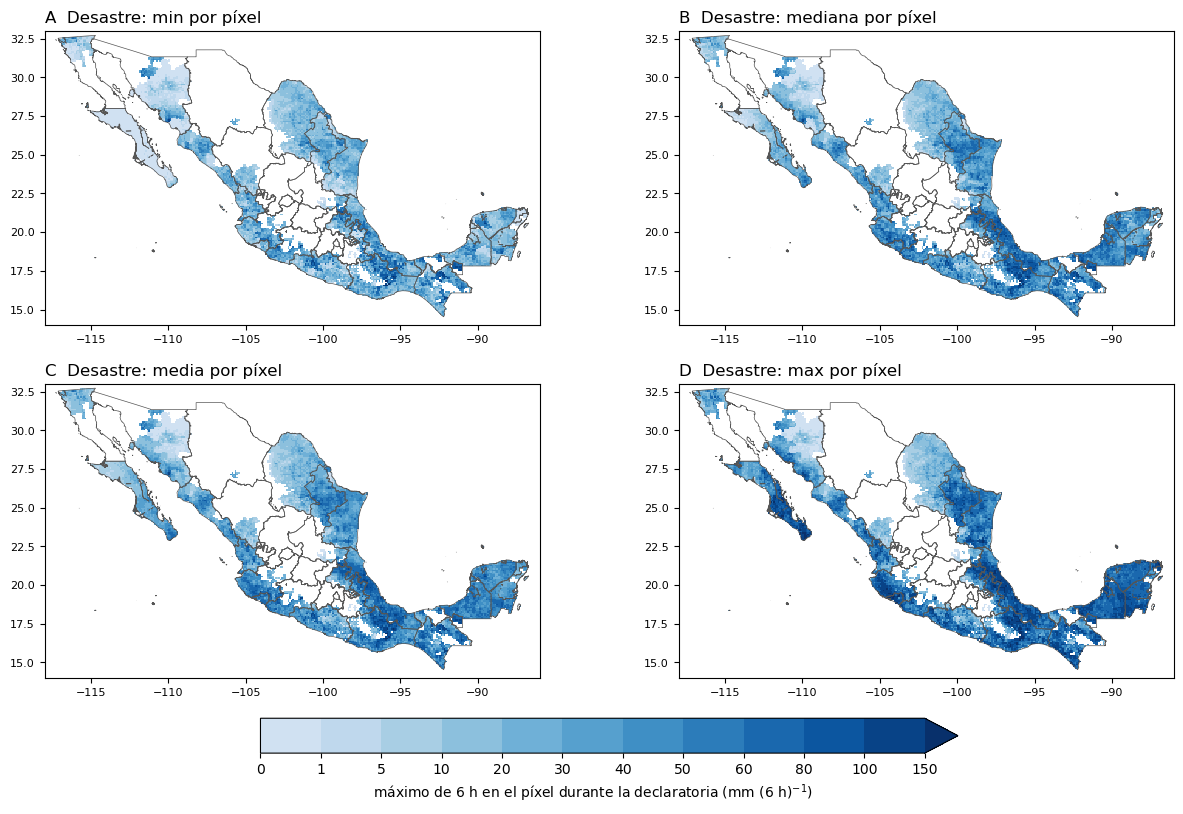

In [3]:
EXT = dict(xlim=(-118, -86), ylim=(14, 33))
B_P = [0, 1, 5, 10, 20, 30, 40, 50, 60, 80, 100, 150]
CMAP_P = ListedColormap(plt.cm.Blues(np.linspace(0.2, 1.0, len(B_P))))   # sin el tramo casi blanco
NORM_P = BoundaryNorm(B_P, CMAP_P.N, extend="max")

s = ps.sel(tipo=TIPO)
ok = s["n_decl"] >= N_MIN

fig, axs = plt.subplots(2, 2, figsize=(15, 10.5))
for ax, k, letra in zip(axs.flat, STATS, "ABCD"):
    m = ax.pcolormesh(s["lon"], s["lat"], s[f"P_{k}"].where(ok), cmap=CMAP_P, norm=NORM_P, shading="auto")
    estados.boundary.plot(ax=ax, color="#555555", lw=0.5)
    ax.set(**EXT, aspect="equal"); ax.tick_params(labelsize=8)
    ax.set_title(f"{letra}  {TIPO}: {k} por píxel", loc="left")
fig.colorbar(m, ax=axs, orientation="horizontal", shrink=0.6, pad=0.05, ticks=B_P,
             label="máximo de 6 h en el píxel durante la declaratoria (mm (6 h)$^{-1}$)")
fig.savefig(FIG / f"fig_pixel_stats_{TIPO}.png", dpi=300, bbox_inches="tight")

## 4. Mapas por municipio

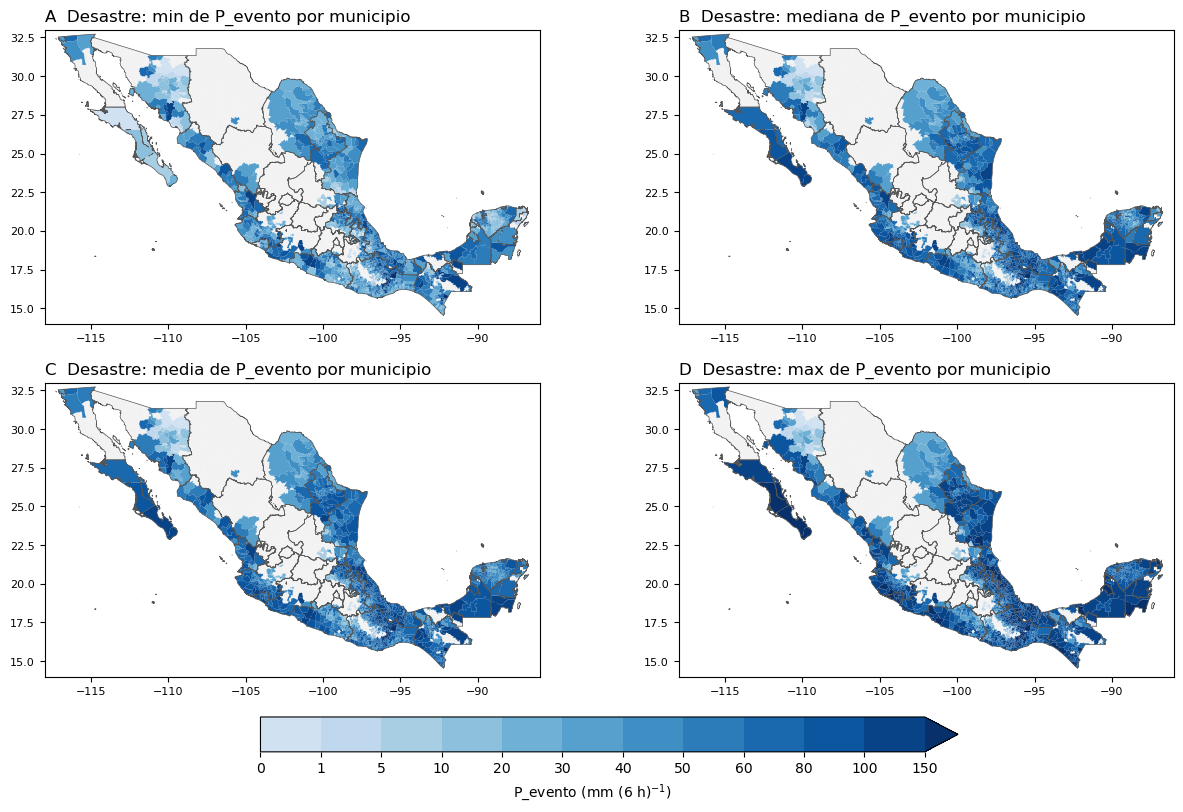

In [4]:
m = gdf_mun[["CVEGEO", "geometry"]].merge(ms[(ms["tipo"] == TIPO) & (ms["n_decl"] >= N_MIN)], on="CVEGEO")

fig, axs = plt.subplots(2, 2, figsize=(15, 10.5))
for ax, k, letra in zip(axs.flat, STATS, "ABCD"):
    gdf_mun.plot(ax=ax, color="#f2f2f2", edgecolor="none")
    m.plot(ax=ax, column=f"{VAR_MUN}_{k}", cmap=CMAP_P, norm=NORM_P, edgecolor="none", zorder=2)
    estados.boundary.plot(ax=ax, color="#555555", lw=0.5, zorder=3)
    ax.set(**EXT, aspect="equal"); ax.tick_params(labelsize=8)
    ax.set_title(f"{letra}  {TIPO}: {k} de {VAR_MUN} por municipio", loc="left")
fig.colorbar(plt.cm.ScalarMappable(norm=NORM_P, cmap=CMAP_P), ax=axs, orientation="horizontal", shrink=0.6,
             pad=0.05, ticks=B_P, label=f"{VAR_MUN} (mm (6 h)$^{{-1}}$)")
fig.savefig(FIG / f"fig_municipio_stats_{VAR_MUN}_{TIPO}.png", dpi=300, bbox_inches="tight")

## 5. Municipios: valores y declaratoria del mínimo y del máximo

In [5]:
cols = ["CVEGEO", "NOMGEO", "NOM_ENT", "n_decl"] + [f"{VAR_MUN}_{k}" for k in STATS] + \
       [f"{VAR_MUN}_Identificador_min", f"{VAR_MUN}_CT_min", f"{VAR_MUN}_t_min",
        f"{VAR_MUN}_Identificador_max", f"{VAR_MUN}_CT_max", f"{VAR_MUN}_t_max", "identificadores"]
tabla_mun = ms[(ms["tipo"] == TIPO) & (ms["n_decl"] >= N_MIN)][cols].sort_values(f"{VAR_MUN}_min")
r1(tabla_mun.head(30))

,CVEGEO,NOMGEO,NOM_ENT,n_decl,P_evento_min,P_evento_mediana,P_evento_media,P_evento_max,P_evento_Identificador_min,P_evento_CT_min,P_evento_t_min,P_evento_Identificador_max,P_evento_CT_max,P_evento_t_max,identificadores
3396,06007,Manzanillo,Colima,13,0.0,81.9,87.7,215.8,20976,EP022015,2015-06-07 00:00:00,15025,EP102011,2011-10-12 12:00:00,1537;7762;15025;18169;19735;19888;20976;21158;...
4340,21211,Zaragoza,Puebla,4,0.0,37.4,37.4,74.7,23403,AL072017,2017-08-09 00:00:00,5833,AL222005,2005-10-06 12:00:00,5833;13401;18210;23403
4334,21205,Yehualtepec,Puebla,1,0.0,0.0,0.0,0.0,23399,AL072017,2017-08-09 00:00:00,23399,AL072017,2017-08-09 00:00:00,23399
4405,26019,Cananea,Sonora,1,0.0,0.0,0.0,0.0,9385,EP112007,2007-09-05 00:00:00,9385,EP112007,2007-09-05 00:00:00,9385
4337,21208,Zacatlán,Puebla,5,0.0,47.4,48.7,98.0,23402,AL072017,2017-08-09 00:00:00,5836,AL222005,2005-10-06 06:00:00,5836;13403;23402;24083;27052
4241,21017,Atempan,Puebla,5,0.0,100.1,83.6,128.5,23371,AL072017,2017-08-09 00:00:00,5926,AL202005,2005-10-04 18:00:00,5926;13430;18237;23371;24072
4240,21016,Aquixtla,Puebla,5,0.0,22.9,43.2,87.4,23370,AL072017,2017-08-09 00:00:00,5927,AL222005,2005-10-06 12:00:00,5927;13431;18238;23370;27052
4318,21173,Teteles de Ávila Castillo,Puebla,4,0.0,100.6,82.4,128.5,23390,AL072017,2017-08-09 00:00:00,5853,AL202005,2005-10-04 18:00:00,5853;13409;18221;23390
4234,21007,Ahuatlán,Puebla,1,0.0,0.0,0.0,0.0,23369,AL072017,2017-08-09 00:00:00,23369,AL072017,2017-08-09 00:00:00,23369
4398,26011,Bacoachi,Sonora,1,0.0,0.0,0.0,0.0,9391,EP112007,2007-09-05 18:00:00,9391,EP112007,2007-09-05 18:00:00,9391


## 6. Consultar un municipio: sus declaratorias y la lluvia en cada píxel

In [6]:
CVEGEO = tabla_mun["CVEGEO"].iloc[0]     # cambiar por la clave (5 dígitos) que se quiera revisar

e = ev[ev["CVEGEO"].eq(CVEGEO)].sort_values("fecha_inicio")
print(gdf_mun.loc[gdf_mun["CVEGEO"].eq(CVEGEO), ["NOMGEO", "NOM_ENT"]].to_string(index=False))
display(r1(e[["Identificador", "Tipo Declaratoria", "Observaciones", "fecha_inicio", "fecha_fin", "CT_pico", "t_pico",
              "dist_pico_km", "P_evento", "P_evento_areal"]]))

# Máximo de 6 h en cada píxel del municipio (filas) para cada declaratoria (columnas)
d = pdcl[pdcl["CVEGEO"].eq(CVEGEO)].copy()
d["declaratoria"] = d["Identificador"].astype(str) + " " + d["Tipo Declaratoria"].str[:4]
d.pivot_table(index=["lat", "lon"], columns="declaratoria", values="P6_pix").round(1)

    NOMGEO NOM_ENT
Manzanillo  Colima


,Identificador,Tipo Declaratoria,Observaciones,fecha_inicio,fecha_fin,CT_pico,t_pico,dist_pico_km,P_evento,P_evento_areal
6779,26326,Emergencia,Depresión tropical Norman con posibles lluvias...,2000-09-19,2000-09-22,EP162000,2000-09-21 18:00:00,159.7,68.6,40.0
6880,26339,Desastre,Lluvias atípicas e impredecibles y por inundac...,2000-09-21,2000-09-22,EP162000,2000-09-21 18:00:00,159.7,68.6,39.1
92,1537,Desastre,"Huracan ""Kena""",2002-10-25,2002-10-25,EP142002,2002-10-25 12:00:00,271.5,79.7,36.4
2235,7762,Desastre,"Huracan ""Lane""",2006-09-14,2006-09-15,EP132006,2006-09-15 00:00:00,146.3,56.3,38.7
2266,7923,Emergencia,"Huracan ""Lane""",2006-09-14,2006-09-15,EP132006,2006-09-15 00:00:00,146.3,56.3,38.7
4641,15025,Desastre,Huracan Jova,2011-10-12,2011-10-12,EP102011,2011-10-12 12:00:00,175.8,215.8,154.1
4651,15036,Emergencia,Huracan Jova,2011-10-12,2011-10-12,EP102011,2011-10-12 12:00:00,175.8,215.8,154.1
4950,16572,Contingencia Climatológica,Huracan Jova Desastre Sagarpa,2011-10-12,2011-10-12,EP102011,2011-10-12 12:00:00,175.8,215.8,154.1
5711,18306,Emergencia,Tormenta tropical Manuel,2013-09-15,2013-09-17,EP132013,2013-09-16 18:00:00,261.4,81.9,49.7
5596,18169,Desastre,Tormenta tropical Manuel,2013-09-16,2013-09-17,EP132013,2013-09-16 18:00:00,261.4,81.9,49.7


declaratoria   15025 Desa  15036 Emer  1537 Desa  16572 Cont  18169 Desa  \
lat   lon                                                                  
19.05 -104.25       145.4       145.4       13.6       145.4        37.1   
      -104.15       122.5       122.5       19.3       122.5        52.3   
      -104.05       118.7       118.7       45.2       118.7        52.3   
19.15 -104.55        85.4        85.4       79.7        85.4        28.4   
      -104.45       197.8       197.8       36.2       197.8        73.5   
      -104.35       173.1       173.1       27.2       173.1        81.9   
      -104.25       125.3       125.3       16.5       125.3        43.5   
      -104.15       190.9       190.9       37.0       190.9        31.6   
19.25 -104.45       171.8       171.8       66.7       171.8        55.4   
      -104.35       110.3       110.3       23.3       110.3        24.6   
      -104.25       215.8       215.8       39.3       215.8        55.5   
      -104.15       192.3       192.3       33.2       192.3        59.8   

declaratoria   18306 Emer  19735 Desa  19888 Desa  20976 Desa  21158 Desa  \
lat   lon                                                                   
19.05 -104.25        37.1         0.0         0.4         0.0       117.4   
      -104.15        52.3         0.8         0.1         0.0       120.4   
      -104.05        52.3         1.0         0.3         0.0       103.7   
19.15 -104.55        28.4         0.0         1.6         0.0       161.4   
      -104.45        73.5         0.0         2.4         0.0       119.5   
      -104.35        81.9         0.2         2.7         0.0       112.1   
      -104.25        43.5         0.0         1.3         0.0       126.7   
      -104.15        31.6         0.9         0.1         0.0       155.9   
19.25 -104.45        55.4         0.0         2.0         0.0       112.0   
      -104.35        24.6         0.0         1.3         0.0        86.6   
      -104.25        55.5         0.0         0.2         0.0       170.8   
      -104.15        59.8         0.2         1.2         0.0       145.8   

declaratoria   ...  26326 Emer  26339 Desa  26842 Desa  26849 Desa  \
lat   lon      ...                                                   
19.05 -104.25  ...        51.3        51.3        63.2        39.8   
      -104.15  ...        42.7        39.6        69.2        38.9   
      -104.05  ...        44.3        44.3        70.9        47.1   
19.15 -104.55  ...        68.6        68.6       106.2        85.9   
      -104.45  ...        49.8        49.8       116.0        64.9   
      -104.35  ...        48.0        48.0        97.5        51.7   
      -104.25  ...        42.9        40.1        65.0        63.4   
      -104.15  ...        48.2        48.2        99.4        51.4   
19.25 -104.45  ...        21.7        21.7       106.2        76.8   
      -104.35  ...        22.8        22.8        70.0        34.8   
      -104.25  ...        18.7        13.8        70.0        58.3   
      -104.15  ...        21.3        21.3        76.6        61.0   

declaratoria   26852 Emer  26962 Emer  26963 Desa  27061 Desa  7762 Desa  \
lat   lon                                                                  
19.05 -104.25        39.8       100.4       100.4        75.3       31.2   
      -104.15        38.9        48.0        48.0        83.2       30.3   
      -104.05        47.1        30.6        30.6        62.8       43.6   
19.15 -104.55        85.9       111.3       111.3       117.0       41.3   
      -104.45        64.9       129.4       129.4        98.6       56.3   
      -104.35        51.7       140.7       140.7        92.7       33.1   
      -104.25        63.4        67.5        67.5        72.6       26.8   
      -104.15        51.4        62.0        62.0       100.8       42.1   
19.25 -104.45        76.8       122.1       122.1       120.3       45.7   
      -104.35        34.8        66.6  

## 7. Consultar un píxel por coordenadas

In [7]:
# Por defecto, el píxel con más declaratorias; cambiar por las coordenadas de interés
_top = pdcl.groupby("ipix")[["lat", "lon"]].first().loc[pdcl["ipix"].value_counts().index[0]]
LAT, LON = float(_top["lat"]), float(_top["lon"])

j = int(np.abs(ps["lat"].values - LAT).argmin()); i = int(np.abs(ps["lon"].values - LON).argmin())
ip = j * ps.sizes["lon"] + i
print(f"Píxel más cercano: {float(ps['lat'][j]):.2f}, {float(ps['lon'][i]):.2f}")
display(ps.isel(lat=j, lon=i).to_dataframe().drop(columns=["lat", "lon"]).round(1))
r1(pdcl[pdcl["ipix"].eq(ip)].sort_values("P6_pix")[["Identificador", "Tipo Declaratoria", "Municipio", "Estado",
                                                     "P6_pix", "t_max_pix", "CT_t_max", "dist_t_max_km"]])

Píxel más cercano: 19.55, -96.95


,n_decl,P_min,P_mediana,P_media,P_max,Identificador_min,Identificador_max
tipo,,,,,,,
todas,55,17.000000,73.000000,81.300003,180.399994,9696.0,17694.0
Emergencia,29,17.000000,64.300003,74.000000,180.399994,9696.0,17694.0
Desastre,26,36.200001,82.400002,89.500000,180.399994,6295.0,17783.0
Contingencia Climatológica,0,NaN,NaN,NaN,NaN,NaN,NaN


,Identificador,Tipo Declaratoria,Municipio,Estado,P6_pix,t_max_pix,CT_t_max,dist_t_max_km
34341,9696,Emergencia,Banderilla,Veracruz de Ignacio de la Llave,17.0,2007-09-27 12:00:00,AL132007,222.2
35406,9581,Emergencia,Tlalnelhuayocan,Veracruz de Ignacio de la Llave,17.0,2007-09-27 12:00:00,AL132007,230.0
35076,9607,Emergencia,Rafael Lucio,Veracruz de Ignacio de la Llave,17.0,2007-09-27 12:00:00,AL132007,226.1
34658,9646,Emergencia,Xalapa,Veracruz de Ignacio de la Llave,17.0,2007-09-27 12:00:00,AL132007,221.8
20510,6295,Desastre,Xalapa,Veracruz de Ignacio de la Llave,36.2,2005-10-04 18:00:00,AL202005,228.2
48548,14442,Desastre,Banderilla,Veracruz de Ignacio de la Llave,40.6,2011-06-30 18:00:00,AL012011,244.6
48671,14314,Emergencia,Xalapa,Veracruz de Ignacio de la Llave,40.6,2011-06-30 18:00:00,AL012011,251.0
48673,14423,Desastre,Xalapa,Veracruz de Ignacio de la Llave,40.6,2011-06-30 18:00:00,AL012011,251.0
48849,14308,Emergencia,Rafael Lucio,Veracruz de Ignacio de la Llave,40.6,2011-06-30 18:00:00,AL012011,241.1
48850,14409,Desastre,Rafael Lucio,Veracruz de Ignacio de la Llave,40.6,2011-06-30 18:00:00,AL012011,241.1


## 8. Por ciclón: declaratorias asociadas

In [8]:
display(cic[["CT", "fecha_inicio_min", "n_decl", "n_emergencia", "n_desastre", "n_contingencia", "n_municipios",
             "estados", "P_evento_min", "P_evento_mediana", "P_evento_media", "P_evento_max"]].round(1))

,CT,fecha_inicio_min,n_decl,n_emergencia,n_desastre,n_contingencia,n_municipios,estados,P_evento_min,P_evento_mediana,P_evento_media,P_evento_max
0,AL052000,2000-08-14,43,43,0,0,43,Tamaulipas,0.0,0.1,4.2,26.4
1,EP142000,2000-09-06,1,0,1,0,1,Michoacán de Ocampo,12.6,12.6,12.6,12.6
2,AL112000,2000-09-17,12,12,0,0,12,Baja California Sur;Guerrero,4.6,12.0,32.7,123.6
3,EP152000,2000-09-17,1,1,0,0,1,Baja California Sur,69.8,69.8,69.8,69.8
4,AL122000,2000-09-19,19,19,0,0,19,Guerrero,4.6,15.1,21.5,53.4
...,...,...,...,...,...,...,...,...,...,...,...,...
134,EP152023,2023-10-09,4,0,4,0,4,Guerrero,7.5,62.3,64.3,125.0
135,EP182023,2023-10-24,4,2,2,0,2,Guerrero,0.0,57.7,60.8,127.9
136,EP112024,2024-09-23,8,8,0,0,8,Guerrero;Oaxaca,53.7,74.6,83.7,135.1
137,EP132024,2024-10-19,22,0,22,0,22,Veracruz de Ignacio de la Llave,39.6,91.9,92.6,170.6


,Identificador,Tipo Declaratoria,Estado,Municipio,Observaciones,fecha_inicio,fecha_fin,t_pico,dist_pico_km,P_evento,P_evento_areal
7530,26371,Emergencia,Oaxaca,Abejones,Tormenta tropical Rosa. No se especifican los ...,2000-11-07,2000-11-10,2000-11-07 00:00:00,526.5,0.0,0.0
7713,26371,Emergencia,Oaxaca,San Juan Bautista Tlacoatzintepec,Tormenta tropical Rosa. No se especifican los ...,2000-11-07,2000-11-10,2000-11-07 00:00:00,566.3,0.0,0.0
7712,26371,Emergencia,Oaxaca,San Juan Bautista Tlachichilco,Tormenta tropical Rosa. No se especifican los ...,2000-11-07,2000-11-10,2000-11-07 00:00:00,489.1,0.0,0.0
7711,26371,Emergencia,Oaxaca,San Juan Bautista Suchitepec,Tormenta tropical Rosa. No se especifican los ...,2000-11-07,2000-11-10,2000-11-07 00:00:00,546.3,0.0,0.0
7709,26371,Emergencia,Oaxaca,San Juan Bautista Jayacatlán,Tormenta tropical Rosa. No se especifican los ...,2000-11-07,2000-11-10,2000-11-07 00:00:00,512.4,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
7245,26370,Emergencia,Oaxaca,San Miguel del Puerto,Tormenta tropical Rosa. No se especifican los ...,2000-11-07,2000-11-10,2000-11-08 12:00:00,44.2,45.3,21.5
7282,26370,Emergencia,Oaxaca,San Pedro Pochutla,Tormenta tropical Rosa. No se especifican los ...,2000-11-07,2000-11-10,2000-11-08 12:00:00,80.1,52.5,42.4
7852,26371,Emergencia,Oaxaca,San Pedro Pochutla,Tormenta tropical Rosa. No se especifican los ...,2000-11-07,2000-11-10,2000-11-08 12:00:00,80.1,52.5,42.4
7370,26370,Emergencia,Oaxaca,Santa María Huatulco,Tormenta tropical Rosa. No se especifican los ...,2000-11-07,2000-11-10,2000-11-08 12:00:00,62.4,78.1,41.0


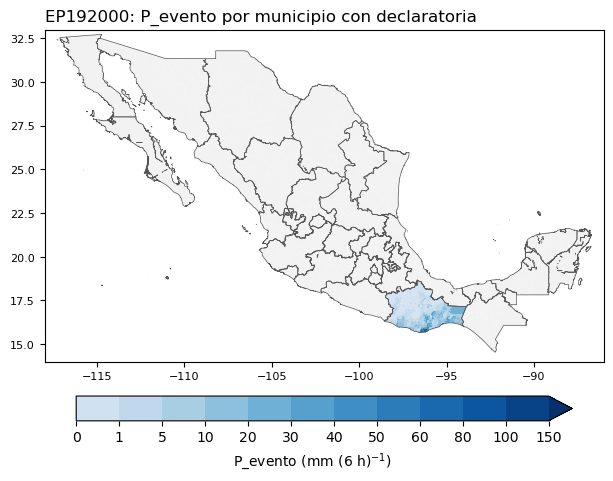

In [9]:
CT = cic.sort_values("n_decl").iloc[-1]["CT"]      # cambiar, p. ej. "AL032020"

e = ev[ev["CT_pico"].eq(CT)]
m = gdf_mun[["CVEGEO", "geometry"]].merge(e.groupby("CVEGEO")["P_evento"].max().reset_index(), on="CVEGEO")

fig, ax = plt.subplots(figsize=(8, 5.6))
gdf_mun.plot(ax=ax, color="#f2f2f2", edgecolor="none")
m.plot(ax=ax, column="P_evento", cmap=CMAP_P, norm=NORM_P, edgecolor="none", zorder=2)
estados.boundary.plot(ax=ax, color="#555555", lw=0.5, zorder=3)
ax.set(**EXT, aspect="equal"); ax.tick_params(labelsize=8)
ax.set_title(f"{CT}: P_evento por municipio con declaratoria", loc="left")
fig.colorbar(plt.cm.ScalarMappable(norm=NORM_P, cmap=CMAP_P), ax=ax, orientation="horizontal", shrink=0.8,
             pad=0.08, ticks=B_P, label="P_evento (mm (6 h)$^{-1}$)")
fig.savefig(FIG / f"fig_ciclon_{CT}.png", dpi=300, bbox_inches="tight")

r1(e[["Identificador", "Tipo Declaratoria", "Estado", "Municipio", "Observaciones", "fecha_inicio", "fecha_fin",
      "t_pico", "dist_pico_km", "P_evento", "P_evento_areal"]].sort_values("P_evento"))